In [69]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [70]:
class BMIState(TypedDict):
    weight_kg : float
    height_m : float
    bmi : float
    label : str

In [71]:
def calculate_bmi(state: BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']

    bmi = weight/(height**2)
    state["bmi"] = round(bmi, 2)

    return state

In [72]:
def BMI_label(state: BMIState) -> BMIState:
    bmi = state["bmi"]
    if bmi < 18.5:
        state["label"] = "UnderWeight"
    elif 18.5 <= bmi < 25:
        state["label"] = "Normal"
    elif 25 <= bmi < 30:
        state["label"] = "OverWeight"
    else:
        state["label"] = "Obese"

    return state

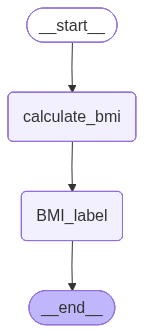

In [73]:
graph = StateGraph(BMIState)

graph.add_node('calculate_bmi', calculate_bmi)

graph.add_node('BMI_label', BMI_label)

graph.add_edge(START, 'calculate_bmi')

graph.add_edge('calculate_bmi', 'BMI_label')

graph.add_edge('BMI_label', END)

workflow = graph.compile()

workflow


In [78]:
input_state = {"weight_kg": 50, "height_m": 5.6}
output_state = workflow.invoke(input_state)
output_state

{'weight_kg': 50, 'height_m': 5.6, 'bmi': 1.59, 'label': 'UnderWeight'}